# Data exploration

In [206]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import sys
import time
from tqdm.auto import tqdm
from itertools import combinations_with_replacement

from preprocess import get_data

In [3]:
# Threads inherit context to avoid issues with parallel processing in some environments
%env PYTHON_THREAD_INHERIT_CONTEXT 1

# Make the context manager safe for parallel processing
%env PYTHON_CONTEXT_AWARE_WARNINGS 1

env: PYTHON_THREAD_INHERIT_CONTEXT=1
env: PYTHON_CONTEXT_AWARE_WARNINGS=1


In [4]:
sys.flags.context_aware_warnings

0

In [5]:
X, y, groups, raw, cols = get_data()

In [6]:
data = pd.DataFrame(X, columns=cols)
data

,mav_channel1,mav_channel2,mav_channel3,mav_channel4,mav_channel5,mav_channel6,mav_channel7,mav_channel8,rms_channel1,rms_channel2,...,mnf_channel7,mnf_channel8,mdf_channel1,mdf_channel2,mdf_channel3,mdf_channel4,mdf_channel5,mdf_channel6,mdf_channel7,mdf_channel8
0,0.058207,0.117303,0.161374,0.074964,0.054525,0.051401,0.058975,0.056942,0.074367,0.147274,...,0.274670,0.235481,0.300,0.200,0.300,0.250,0.250,0.175,0.300,0.175
1,0.062381,0.113969,0.169086,0.074337,0.049334,0.053639,0.059120,0.055335,0.077652,0.147918,...,0.214525,0.246612,0.300,0.275,0.300,0.275,0.325,0.175,0.175,0.200
2,0.057390,0.110414,0.174869,0.073762,0.047709,0.053111,0.059048,0.055178,0.073632,0.151400,...,0.258989,0.299320,0.200,0.200,0.325,0.300,0.300,0.225,0.250,0.300
3,0.065164,0.106860,0.157324,0.089810,0.044460,0.054104,0.054862,0.060939,0.083835,0.146307,...,0.273076,0.299515,0.325,0.250,0.275,0.350,0.250,0.200,0.300,0.250
4,0.067373,0.103967,0.155006,0.095246,0.041211,0.056870,0.061286,0.055178,0.085241,0.143911,...,0.282890,0.297128,0.275,0.275,0.275,0.350,0.175,0.200,0.325,0.300
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13330,0.172631,0.271292,0.268063,0.263990,0.431870,0.982343,0.571994,0.810268,0.244502,0.319906,...,0.262333,0.253427,0.275,0.350,0.375,0.325,0.275,0.250,0.275,0.250
13331,0.218848,0.250761,0.282093,0.238375,0.451909,0.871446,0.561227,0.738952,0.357259,0.309183,...,0.260103,0.262468,0.300,0.350,0.400,0.275,0.250,0.250,0.275,0.250
13332,0.361454,0.288182,0.229366,0.248970,0.498217,1.107575,0.583402,0.769635,0.595096,0.373942,...,0.247645,0.252823,0.300,0.325,0.350,0.275,0.275,0.275,0.275,0.250
13333,0.416166,0.274670,0.197846,0.219824,0.500802,1.192589,0.670761,0.831001,0.625497,0.354376,...,0.237130,0.284483,0.300,0.300,0.250,0.225,0.275,0.250,0.275,0.375


In [7]:
raw_data = pd.DataFrame(raw[:,:,0])
raw_data

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,-0.005450,-0.005450,-0.005450,-0.005450,-0.072005,0.061106,-0.072005,-0.005450,-0.072005,-0.005450,...,0.127661,0.061106,-0.138561,0.127661,0.061106,-0.005450,0.061106,-0.072005,-0.005450,-0.072005
1,0.061106,0.061106,-0.005450,-0.005450,0.127661,-0.072005,-0.138561,0.061106,-0.072005,-0.138561,...,0.061106,0.061106,-0.005450,0.061106,0.061106,-0.072005,-0.005450,-0.138561,-0.005450,-0.005450
2,-0.138561,-0.005450,-0.005450,0.061106,0.127661,0.061106,-0.072005,0.061106,-0.005450,-0.005450,...,-0.005450,-0.005450,-0.138561,-0.005450,0.061106,0.061106,0.127661,0.061106,-0.072005,-0.005450
3,0.127661,0.061106,-0.138561,0.127661,0.061106,-0.005450,0.061106,-0.072005,-0.005450,-0.072005,...,0.061106,0.061106,-0.072005,0.127661,0.061106,-0.005450,0.061106,-0.005450,0.194216,-0.205116
4,0.061106,0.061106,-0.005450,0.061106,0.061106,-0.072005,-0.005450,-0.138561,-0.005450,-0.005450,...,-0.072005,-0.072005,-0.072005,0.127661,0.061106,-0.005450,-0.138561,-0.072005,0.061106,-0.138561
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13330,-0.094788,-0.260699,0.126426,0.015819,0.071123,-0.039485,0.015819,0.126426,0.015819,0.624159,...,0.126426,0.237034,0.015819,-0.150092,0.015819,0.568855,0.126426,-0.703128,0.347641,0.015819
13331,-0.205395,0.015819,0.071123,-0.426610,-0.094788,0.126426,-0.094788,0.237034,0.181730,0.237034,...,0.126426,-0.150092,0.181730,0.126426,-1.698592,0.347641,-0.260699,0.126426,0.015819,-0.205395
13332,-0.426610,-0.205395,-0.039485,0.181730,0.015819,-0.039485,-0.371306,0.015819,-0.150092,0.071123,...,-0.537217,0.568855,0.790069,-2.251628,0.513551,0.347641,0.458248,0.015819,0.347641,1.564320
13333,0.126426,0.237034,0.015819,-0.150092,0.015819,0.568855,0.126426,-0.703128,0.347641,0.015819,...,-0.869038,-0.150092,0.347641,-0.205395,0.402944,0.237034,-0.150092,0.734766,0.347641,-0.260699


In [8]:
range(raw.shape[-1])

range(0, 8)

# Main code

## Preamble

In [9]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.callback import ProgressBar
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.exceptions import ConvergenceWarning, FitFailedWarning, UndefinedMetricWarning
from sklearn.experimental import enable_halving_search_cv
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score, GridSearchCV, GroupKFold, GroupShuffleSplit, HalvingGridSearchCV, RandomizedSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import FeatureUnion, make_pipeline, make_union, Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.utils import estimator_html_repr

### Constants definition

In [238]:
ALLOW_OVERWRITE = False
CUSTOM_NAMES = True
SCORING = None
RANDOM_STATE = 42

uniform_spacer = lambda x, y: (pow(10, x), pow(10, y), int(np.log10(pow(10, y) / pow(10, x))) + 1)
C_OPTS = np.geomspace(*uniform_spacer(-3, 3), dtype=float).tolist()
GAMMA_OPTS = ['scale', 'auto'] #+ np.geomspace(*uniform_spacer(-3, -1), dtype=float).tolist()
COEF0_OPTS = [0, 1, 5]
ALPHA_OPTS = np.geomspace(*uniform_spacer(-4, -1), dtype=float).tolist()
ACTIVATION_OPTS = ['identity', 'logistic', 'tanh', 'relu']
LR_INIT_OPTS = np.geomspace(*uniform_spacer(-4, -1), dtype=float).tolist()
MOMENTUM_OPTS = [0.9, 0.99]
MIN_SAMPLES_SPLIT_OPTS = [2, 3, 4]
MAX_FEATURES_OPTS = ['sqrt', 'log2', None, 0.3, 0.5, 0.7]
CCP_ALPHA_OPTS = [0.0] + np.geomspace(*uniform_spacer(-3, -1), dtype=float).tolist()

OPTIONS = {
    'preprocessing': {
        "window_samples": [10, 20, 30, 40],
        "overlap": [0, 0.25, 0.5, 0.75],
        "normalization": ["none", "global", "per_subject"],
        "zc_threshold": [0.05, 0.1, 0.2],
    },
    'lineardiscriminantanalysis': [
        {
            'solver': ['svd'],
        }, {
            'solver': ['lsqr', 'eigen'],
            'shrinkage': [None, 'auto'],
        }
    ],
    'randomforestclassifier': [
        {
            'n_estimators': [125],
            'max_depth': [10],
            'min_samples_split': MIN_SAMPLES_SPLIT_OPTS,
            'max_features': MAX_FEATURES_OPTS,
            'bootstrap': [True],
            'oob_score': [True, False],
            'class_weight': [None, 'balanced', 'balanced_subsample'],
            'ccp_alpha': CCP_ALPHA_OPTS,
        }, {
            'n_estimators': [125],
            'max_depth': [10],
            'min_samples_split': MIN_SAMPLES_SPLIT_OPTS,
            'max_features': MAX_FEATURES_OPTS,
            'bootstrap': [False],
            'class_weight': [None, 'balanced', 'balanced_subsample'],
            'ccp_alpha': CCP_ALPHA_OPTS,
        },
    ],
    'votingclassifier': {
            'voting': ['soft', 'hard'],
    },
    'logisticregression': [
        {
            'C': C_OPTS,
            'l1_ratio': [0, 0.25, 0.5, 0.75, 1],
            'class_weight': [None, 'balanced'],
            'solver': ['saga'],
        }, {
            'C': [np.inf],
            'class_weight': [None, 'balanced'],
            'solver': ['saga'],
        }, {
            'C': C_OPTS + [np.inf],
            'class_weight': [None, 'balanced'],
            'solver': ['lbfgs', 'newton-cg', 'sag'],
        }
    ],
    'kneighborsclassifier': {
        'n_neighbors': [70],
        'weights': ['uniform', 'distance', None],
        'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
        'p': [1, 1.5, 2, 3],
    },
    'mlpclassifier': [
        {
            'hidden_layer_sizes': [(100, 50)],
            'activation': ACTIVATION_OPTS,
            'solver': ['lbfgs'],
            'alpha': ALPHA_OPTS,
        }, {
            'hidden_layer_sizes': [(100, 50)],
            'activation': ACTIVATION_OPTS,
            'solver': ['sgd'],
            'alpha': ALPHA_OPTS,
            'learning_rate': ['constant', 'adaptive'],
            'learning_rate_init': LR_INIT_OPTS,
            'momentum': MOMENTUM_OPTS,
        }, {
            'hidden_layer_sizes': [(100, 50)],
            'activation': ACTIVATION_OPTS,
            'solver': ['sgd'],
            'alpha': ALPHA_OPTS,
            'learning_rate': ['invscaling'],
            'learning_rate_init': LR_INIT_OPTS,
            'power_t': [0.5, 1.0, 2.0],
            'momentum': MOMENTUM_OPTS,
        }, {
            'hidden_layer_sizes': [(100, 50)],
            'activation': ACTIVATION_OPTS,
            'solver': ['adam'],
            'alpha': ALPHA_OPTS,
            'learning_rate_init': LR_INIT_OPTS,
            'beta_1': [0.9, 0.999],
            'beta_2': [0.9, 0.999],
            'epsilon': np.geomspace(*uniform_spacer(-9, -7), dtype=float).tolist(),
        }
    ],
    'svc': [
        {
            'C': C_OPTS,
            'kernel': ['linear'],
            'shrinking': [True, False],
            'class_weight': [None, 'balanced'],
            'break_ties': [True, False],
        }, {
            'C': C_OPTS,
            'kernel': ['rbf'],
            'gamma': GAMMA_OPTS,
            'shrinking': [True, False],
            'class_weight': [None, 'balanced'],
            'break_ties': [True, False],
        }, {
            'C': C_OPTS,
            'kernel': ['sigmoid'],
            'gamma': GAMMA_OPTS,
            'coef0': COEF0_OPTS,
            'shrinking': [True, False],
            'class_weight': [None, 'balanced'],
            'break_ties': [True, False],
        }, {
            'C': C_OPTS,
            'kernel': ['poly'],
            'degree': [2, 3, 4],
            'gamma': GAMMA_OPTS,
            'coef0': COEF0_OPTS,
            'shrinking': [True, False],
            'class_weight': [None, 'balanced'],
            'break_ties': [True, False],
        },
    ],
}
TUNED_PARAMS = {
    'preprocessing': {
        'window_samples': 40,
        'overlap': 0.75,
        'normalization': 'per_subject',
        'zc_threshold': 0.2,
    },
    'pca': {
        'n_components': 23,
        'random_state': RANDOM_STATE,
    },
    'lineardiscriminantanalysis': {
        'solver': 'lsqr',
        'shrinkage': 'auto',
    },
    'randomforestclassifier': {
        'bootstrap': True,
        'ccp_alpha': 0.0,
        'class_weight': 'balanced',
        'max_features': 'log2',
        'max_depth': 10,
        'min_samples_split': 4,
        'n_estimators': 125,
        'oob_score': False,
        'random_state': RANDOM_STATE,
    },
    'votingclassifier': {
            'voting': 'hard',
    },
    'selectkbest': {
        'k': 39,
    },
    'logisticregression': {
        'C': 0.001,
        'class_weight': 'balanced',
        'solver': 'lbfgs',
        'random_state': RANDOM_STATE,
    },
    'kneighborsclassifier': {
        'algorithm': 'auto',
        'n_neighbors': 70,
        'p': 1,
        'weights': 'distance',
    },
    'mlpclassifier': {
        'activation': 'logistic',
        'alpha': 0.1,
        'hidden_layer_sizes': (100, 50),
        'learning_rate': 'constant',
        'learning_rate_init': 0.001,
        'momentum': 0.9,
        'solver': 'sgd',
        'random_state': RANDOM_STATE,
    },
    'svc': {
        'C': 1.0,
        'break_ties': False,
        'class_weight': 'balanced',
        'gamma': 'scale',
        'kernel': 'rbf',
        'shrinking': False,
        # 'probability': True,
        'random_state': RANDOM_STATE,
    },
}

### Helper functions

In [11]:
def get_pipeline(*transformers, model, params=None):
    steps = {}
    
    if transformers:
        for i, transformer in enumerate(transformers, start=1):
            if isinstance(transformer, (tuple, list)):
                assert len(transformer) > 1, "Feature sets must be composed of multiple transformers."
                transformer = [get_instance_from_name(tf) for tf in transformer] if isinstance(transformer[0], str) else transformer
                steps[f"transformer_{i}"] = FeatureUnion([(f'transformer_{i}.{j}', tf) for j, tf in enumerate(transformer, start=1)]) if CUSTOM_NAMES else make_union(*transformer)
            else:
                transformer = get_instance_from_name(transformer) if isinstance(transformer, str) and not transformer == "passthrough" else transformer
                steps[f"transformer_{i}"] = transformer
    
    if isinstance(model, (tuple, list)):
        assert len(model) > 1, "Ensemble models must be composed of multiple models."
        model = [get_instance_from_name(m) for m in model] if isinstance(model[0], str) else model
        if CUSTOM_NAMES:
            steps['ensemble_model'] = VotingClassifier([(f'model_{j}', m) for j, m in enumerate(model, start=1)])
        else:
            steps['ensemble_model'] = VotingClassifier([(m.__class__.__name__.lower(), m) for j, m in enumerate(model, start=1)])
    else:
        model = get_instance_from_name(model) if isinstance(model, str) else model
        steps['model'] = model
    
    pipeline = Pipeline(list(steps.items())) if CUSTOM_NAMES else make_pipeline(*steps.values())
    if params:
        pipeline.set_params(**{f"{key.rsplit('__', 1)[0]}__{param}": value for key in get_step_names(pipeline, prefix=True) for param, value in params.get(key.rsplit('__', 1)[-1], {}).items()})
    assert len(get_step_names(pipeline)) == len(get_step_names(pipeline, prefix=True)), "Feature sets must be disjoint. Please ensure that the transformers provided are unique."
    
    return pipeline

In [12]:
def get_step_names(pipeline, prefix=False):
    step_names = {}
    for name, step in pipeline.named_steps.items():
        if isinstance(step, str) or step is None:
            step_names[str(step).lower() if not prefix else f"{name}__{str(step).lower()}"] = step
        elif isinstance(step, FeatureUnion):
            step_names[step.__class__.__name__.lower() if not prefix else f"{name}__{step.__class__.__name__.lower()}"] = step
            for sub_name, sub_step in step.named_transformers.items():
                step_names[sub_step.__class__.__name__.lower() if not prefix else f"{name}__{sub_name}__{sub_step.__class__.__name__.lower()}"] = sub_step
        elif isinstance(step, VotingClassifier):
            step_names[step.__class__.__name__.lower() if not prefix else f"{name}__{step.__class__.__name__.lower()}"] = step
            for sub_name, sub_step in step.named_estimators.items():
                step_names[sub_step.__class__.__name__.lower() if not prefix else f"{name}__{sub_name}__{sub_step.__class__.__name__.lower()}"] = sub_step
        else:
            step_names[step.__class__.__name__.lower() if not prefix else f"{name}__{step.__class__.__name__.lower()}"] = step
    return step_names

In [13]:
def get_param_grid(pipeline, warn_missing=True):
    param_grid = {}
    names = get_step_names(pipeline, prefix=True)
    for i, name in enumerate(names):
        prefix, key = name.rsplit('__', 1)
        try:
            if isinstance(param_grid, list):
                if isinstance(OPTIONS[key], list):
                    param_grid = [grid.copy() for grid in param_grid for _ in range(len(OPTIONS[key]))]
                    for k in range(0, len(param_grid), len(OPTIONS[key])):
                        for j, entry in enumerate(OPTIONS[key]):
                            param_grid[k + j].update({f"{prefix}__{param_name}": param_values for param_name, param_values in entry.items()})
                else:
                    for grid in param_grid:
                        grid.update({f"{prefix}__{param_name}": param_values for param_name, param_values in OPTIONS[key].items()})
            else:
                if isinstance(OPTIONS[key], list):
                    param_grid = [param_grid.copy() for _ in range(len(OPTIONS[key]))]
                    for j, entry in enumerate(OPTIONS[key]):
                        param_grid[j].update({f"{prefix}__{param_name}": param_values for param_name, param_values in entry.items()})
                else:
                    param_grid.update({f"{prefix}__{param_name}": param_values for param_name, param_values in OPTIONS[key].items()})
        except KeyError:
            if warn_missing:
                print(f"Warning: No tunable parameters found for step '{key}' in OPTIONS dictionary.")
    return param_grid

In [166]:
def tune_pipeline_parameters(pipeline, X, y, groups, param_grid:list[dict]|dict|None=None, search_strategy:str|None=None, search_space_threshold:int=5000, scoring=None, refit=None, factor:int|float=3, n_trials:int=1, n_splits:int=5, n_jobs:int|None=None, random_state:int|None=None, verbosity:int|str='pbar') -> list[dict]:
    global ALLOW_OVERWRITE; ALLOW_OVERWRITE = True
    best_models = [{'best_estimator_': None, 'best_params_': None, 'best_score_': -np.inf}.copy() for _ in range(n_trials)]
    param_grid = get_param_grid(pipeline) if param_grid is None else param_grid
    candidates = sum([np.prod([len(v) for v in grid.values()]) for grid in param_grid] if isinstance(param_grid, list) else [np.prod([len(v) for v in param_grid.values()])])
    pipe = pipeline
    
    if not refit:
        refit = scoring[0] if not isinstance(scoring, (str, type(None))) else True
    if not search_strategy:
        search_strategy = ('random' if candidates > 10*search_space_threshold else 'halving') if candidates > search_space_threshold else 'grid'
    if not n_jobs in [1, None]:
        for key, value in get_step_names(pipeline, prefix=True).items():
            if hasattr(value, 'n_jobs'):
                pipe.set_params(**{f'{key.rsplit("__", 1)[0]}__n_jobs': n_jobs})
    pipe.set_params(**{f'{key.rsplit('__', 1)[0]}__random_state': random_state for key, value in get_step_names(pipeline, prefix=True).items() if hasattr(value, 'random_state')})
    
    for trial in tqdm(range(n_trials)) if n_trials > 1 and not verbosity == 'pbar' else range(n_trials):
        r_state = (trial + 1) * random_state if random_state is not None else None
        
        if search_strategy == 'grid':
            print(f"Warning: Hyperparameter search space is very large. Exhaustive search may take a long time to complete. Consider using 'halving' search strategy or reducing the search space.") if candidates > search_space_threshold else None
            search = GridSearchCV(pipe, param_grid, scoring=scoring, n_jobs=n_jobs, refit=refit, cv=StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=r_state))
        elif search_strategy == 'halving':
            search = HalvingGridSearchCV(pipe, param_grid, factor=factor, scoring=scoring, n_jobs=n_jobs, refit=refit, cv=StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=r_state))
        elif search_strategy == 'random':
            search = RandomizedSearchCV(pipe, param_distributions=param_grid, n_iter=100, scoring=scoring, n_jobs=n_jobs, refit=refit, cv=StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=r_state), random_state=r_state)
        else:
            raise ValueError("Invalid search strategy. Please choose from ['grid', 'halving', 'random', None].")
        
        if verbosity == 'pbar':
            search.set_callbacks(ProgressBar(max_propagation_depth=0))
            print(f"Search over {n_splits} folds with {candidates} hyperparameter combinations, totalling {candidates * n_splits} evaluations.") if trial == 0 else None
        else:
            search.set_params(**{'verbose': verbosity})
        
        try:
            search.fit(X, y, groups=groups)
            if search.best_score_ > best_models[trial]['best_score_']:
                best_models[trial]['best_estimator_'] = search.best_estimator_
                best_models[trial]['best_params_'] = search.best_params_
                best_models[trial]['best_score_'] = search.best_score_
        except KeyboardInterrupt:
            ALLOW_OVERWRITE = False
            print(f"Interrupted during trial {trial}. Returning best model found so far, but prohibiting overwrites.")
            break
    
    print(f"Overwrite status: {ALLOW_OVERWRITE}")
    
    return best_models

In [92]:
def test_individual_parameter(pipeline, X, y, groups, param, step_idx, scoring=None, n_splits:int=5, n_jobs:int|None=None, random_state:int|None=None, verbose=0):
    scores = {}
    name, values = zip(*param.items())
    
    for value in tqdm(values[0], desc=f"Testing parameter '{name[0]}' for step '{list(get_step_names(pipeline, prefix=True))[step_idx].rsplit('__', 1)[-1]}'", leave=False):
        pipe = pipeline
        pipe.set_params(**{f'{list(get_step_names(pipeline, prefix=True).keys())[step_idx].rsplit('__', 1)[0]}__{name[0]}': value})
        # pipe.set_callbacks(ProgressBar(max_propagation_depth=0)) if verbose == 0 else None
        
        scores[str(value)] = cross_val_score(pipe, X, y, groups=groups, scoring=scoring, cv=StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state), n_jobs=n_jobs, verbose=verbose).mean()
    
    return scores

In [16]:
def tune_preprocessing_parameters(pipeline, param, scoring=None, n_splits:int=5, n_jobs:int|None=None, random_state:int|None=None, verbose:int=0):
    train_scores, test_scores = {}, {}
    name, values = zip(*param.items())
    
    for value in tqdm(values[0], desc=f"Tuning {name[0]}", leave=False):
        pipe = pipeline
        
        if name[0] == 'normalization' and value == 'global':
            X, _, groups, _, _ = get_data(**{name[0]: 'none'})
            # pipe.set_params(**{list(pipeline.named_steps.keys())[0]: StandardScaler()})
            X, y, groups, _, _ = get_data(**{name[0]: value}, fit_idx=next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=random_state).split(X, groups=groups))[0])
        else:
            X, y, groups, _, _ = get_data(**{name[0]: value})
            # pipe.set_params(**{list(pipeline.named_steps.keys())[0]: "passthrough"})
        
        train_index, test_index = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=random_state).split(X, y, groups))
        X_train, X_test, y_train, y_test, groups_train, groups_test = X[train_index], X[test_index], y[train_index], y[test_index], groups[train_index], groups[test_index]

        pipe.fit(X_train, y_train)
        train_scores[str(value)] = cross_val_score(pipe, X_train, y_train, groups=groups_train, scoring=scoring, cv=StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state), n_jobs=n_jobs, verbose=verbose).mean()
        test_scores[str(value)] = pipe.score(X_test, y_test)
    
    return train_scores, test_scores

In [17]:
def get_best_model(models, full_output=False):
    counts = pd.Series([m['best_params_'] for m in models]).value_counts()
    best_p = counts[counts == counts.max()].index.tolist()
    best_s = max([m['best_score_'] for p in best_p for m in models if m['best_params_'] == p])
    best_m = [m for p in best_p for m in models if m['best_params_'] == p and m['best_score_'] == best_s]
    if len(best_m) > 1:
        print(f"Warning: Multiple unique best models found with the same score ({len(best_m)})")
        if full_output:
            raise NotImplementedError("Multiple best models found. Please implement a strategy to select one of them.")
        #     return best_m
    return best_m[0]

In [18]:
def get_instance_from_name(name):
    match name.strip().lower():
        case "knn" | "kneighborsclassifier":
            instance=KNeighborsClassifier()
        case "lda" | "lineardiscriminantanalysis":
            instance=LinearDiscriminantAnalysis()
        case "lr" | "logisticregression":
            instance=LogisticRegression()
        case "mlp" | "mlpclassifier":
            instance=MLPClassifier()
        case "pca":
            instance=PCA()
        case "rf" | "randomforestclassifier":
            instance=RandomForestClassifier()
        case "skb" | "kbest" | "selectkbest":
            instance=SelectKBest()
        case "svc" | "supportvectorclassifier":
            instance=SVC()
        case _:
            raise ValueError(f"Invalid model type: {name}. Please choose from ['lda', 'rf', 'lr', 'knn', 'mlp', 'svc'] or ['pca', 'kbest'].")
    return instance

In [132]:
def split_data_with_groups(n_splits=5, test_size=0.2, random_state:int|None=None, **kwargs):
    X, y, groups, _, _ = get_data(**kwargs)

    # X_train, X_test, y_train, y_test, groups_train, groups_test = train_test_split(X, y, groups, test_size=0.2, random_state=42, stratify=y)
    train_index, test_index = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=random_state).split(X, y, groups))
    X_train, X_test, y_train, y_test, groups_train, groups_test = X[train_index], X[test_index], y[train_index], y[test_index], groups[train_index], groups[test_index]

    print(f"Train size: {X_train.shape} with groups {np.unique(groups_train).tolist()}")
    print(f"Test size: {X_test.shape} with groups {np.unique(groups_test).tolist()}")
    print(f"Check that the train and test groups are disjoint: {set(np.unique(groups_train)).isdisjoint(set(np.unique(groups_test)))}")

    return X_train, X_test, y_train, y_test, groups_train, groups_test

## Initial tuning

Before any tuning of models is done, we want to check a baseline of how the models perform

In [126]:
X_train, X_test, y_train, y_test, groups_train, groups_test = split_data_with_groups(random_state=RANDOM_STATE)

Train size: (10197, 56) with groups [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15, 16, 18, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 33, 34, 35]
Test size: (3138, 56) with groups [13, 14, 17, 22, 27, 31, 32, 36]
Check that the train and test groups are disjoint: True


In [ ]:
with warnings.catch_warnings():
    [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
    display(pd.DataFrame.from_dict({m: [
        cross_val_score(p, X_train, y_train, groups=groups_train, cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1).mean(), 
        p.fit(X_train, y_train).score(X_test, y_test)
        ] for m in tqdm([
            LinearDiscriminantAnalysis(), 
            RandomForestClassifier(random_state=RANDOM_STATE), 
            LogisticRegression(random_state=RANDOM_STATE), 
            KNeighborsClassifier(), 
            MLPClassifier(random_state=RANDOM_STATE), 
            SVC(random_state=RANDOM_STATE)
            ], leave=False) for p in get_pipeline(model=m)}, orient='index', columns=['Train Score', 'Test Score']).sort_values(by='Train Score', ascending=False).reset_index(names='Models'))

  0%|          | 0/6 [00:00<?, ?it/s]

,Models,Train Score,Test Score
0,SVC(random_state=42),0.875232,0.884959
1,LinearDiscriminantAnalysis(),0.872076,0.864563
2,"(DecisionTreeClassifier(max_features='sqrt', r...",0.871255,0.893244
3,LogisticRegression(random_state=42),0.862033,0.864563
4,KNeighborsClassifier(),0.849328,0.854366
5,MLPClassifier(random_state=42),0.845778,0.845443


### Pre-processing parameters sweep

There are some parameters of the preprocessing stage that we would like to tune a bit, so we take any untuned model from above to compare their performance. We find that larger window size and overlap boosts performance ever so slightly. Furthermore, normalizing per subject is much better than normalizing over the entire dataset, while changing the zero crossing threshold seems to impact generalization balance and thus we take the middle value. 

In [122]:
for param in tqdm(OPTIONS['preprocessing']):
    with warnings.catch_warnings():
        [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
        train_scores, test_scores = tune_preprocessing_parameters(get_pipeline(model=SVC(random_state=RANDOM_STATE)), param={param: OPTIONS['preprocessing'][param]}, n_jobs=-1, random_state=RANDOM_STATE)
        display(pd.DataFrame.from_dict(train_scores, orient='index', columns=['train_score']).join(
            pd.DataFrame.from_dict(test_scores, orient='index', columns=['test_score'])).sort_values(by='train_score', ascending=False).reset_index(names=param))

  0%|          | 0/4 [00:00<?, ?it/s]

Tuning window_samples:   0%|          | 0/4 [00:00<?, ?it/s]

,window_samples,train_score,test_score
0,40,0.875232,0.884959
1,20,0.875185,0.870096
2,30,0.869837,0.879873
3,10,0.845782,0.843499


Tuning overlap:   0%|          | 0/4 [00:00<?, ?it/s]

,overlap,train_score,test_score
0,0.75,0.875232,0.884959
1,0.5,0.873925,0.884639
2,0,0.872672,0.886311
3,0.25,0.870578,0.881508


Tuning normalization:   0%|          | 0/3 [00:00<?, ?it/s]

,normalization,train_score,test_score
0,per_subject,0.875232,0.884959
1,none,0.836545,0.832059
2,global,0.834766,0.839707


Tuning zc_threshold:   0%|          | 0/3 [00:00<?, ?it/s]

,zc_threshold,train_score,test_score
0,0.1,0.875232,0.884959
1,0.2,0.874081,0.885915
2,0.05,0.873435,0.886233


In [128]:
X_train, X_test, y_train, y_test, groups_train, groups_test = split_data_with_groups(random_state=RANDOM_STATE, **TUNED_PARAMS['preprocessing'])

Train size: (10197, 56) with groups [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15, 16, 18, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 33, 34, 35]
Test size: (3138, 56) with groups [13, 14, 17, 22, 27, 31, 32, 36]
Check that the train and test groups are disjoint: True


### Dimension reduction of the feature space

We also check the effects of reducing the dimension of the feature space. We observe that **23** PCA components already covers 99.9% of the cumulative explained variance. Furthermore, the expected drop in performance is insignificantly small. We also see that the performance of the model only really starts to drop below 37 original features used. Taking a slight buffer leaves us with **39** original features. 

n_components for 99.9% cumulative explained variance: 23
Explained variance: 0.9993


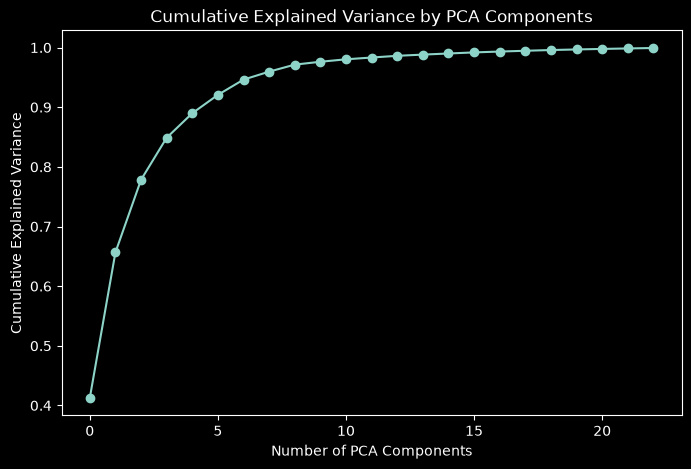

In [129]:
pca = PCA(random_state=RANDOM_STATE).fit(X_train)

cumulative_variance = pca.explained_variance_ratio_.cumsum()
n_components_999 = np.searchsorted(cumulative_variance, 0.999) + 1

plt.figure(figsize=(8, 5))
plt.plot(cumulative_variance[:n_components_999], marker='o')
plt.title("Cumulative Explained Variance by PCA Components")
plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")

print(f"n_components for 99.9% cumulative explained variance: {n_components_999}")
print(f"Explained variance: {cumulative_variance[n_components_999 - 1]:.4f}")

In [130]:
for tf, p, v in zip([PCA(random_state=RANDOM_STATE), SelectKBest()], ['n_components', 'k'], [None, 'all']):
    with warnings.catch_warnings():
        [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
        display(pd.DataFrame.from_dict(
            test_individual_parameter(get_pipeline(tf, model=SVC(random_state=RANDOM_STATE)), X_train, y_train, groups_train, param={p: list(range(1, X_train.shape[1], 2)) + [v]}, step_idx=0, n_jobs=-1, random_state=RANDOM_STATE), 
            orient='index', columns=['Train Score']).assign(Mistakes=lambda x: (1 - x['Train Score']) * len(X_train)).astype({'Mistakes': 'int64'}).sort_values(by='Train Score', ascending=False).reset_index(names=p))

Testing parameter 'n_components' for step 'pca':   0%|          | 0/29 [00:00<?, ?it/s]

,n_components,Train Score,Mistakes
0,21,0.875753,1266
1,19,0.875370,1270
2,17,0.875324,1271
3,37,0.874839,1276
4,29,0.874839,1276
5,45,0.874839,1276
6,39,0.874839,1276
7,23,0.874766,1277
8,33,0.874748,1277
9,27,0.874748,1277


Testing parameter 'k' for step 'selectkbest':   0%|          | 0/29 [00:00<?, ?it/s]

,k,Train Score,Mistakes
0,39,0.875004,1274
1,41,0.875000,1274
2,45,0.874776,1276
3,43,0.874764,1277
4,47,0.874374,1281
5,53,0.874258,1282
6,55,0.874177,1283
7,51,0.874168,1283
8,49,0.874165,1283
9,all,0.874081,1283


The final test we perform here is to see which orientation/combination of dimension reduction step(s) gives us the best performance

In [131]:
d = {}
for tf, s in zip(
    [[SelectKBest(k=39)], [PCA(n_components=23,random_state=RANDOM_STATE)], [SelectKBest(k=39), PCA(n_components=23,random_state=RANDOM_STATE)], [(SelectKBest(k=39), PCA(n_components=23,random_state=RANDOM_STATE))]], 
    ['SelectKBest', 'PCA', 'SelectKBest + PCA', 'SelectKBest + PCA (FeatureUnion)']):
    with warnings.catch_warnings():
        [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
        p = get_pipeline(*tf, model=SVC(random_state=RANDOM_STATE)).fit(X_train, y_train)
        # display(p.score(X_test, y_test))
        d[s] = [
                cross_val_score(p, X_train, y_train, groups=groups_train, cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1).mean(), 
                p.fit(X_train, y_train).score(X_test, y_test)
                ]
display(pd.DataFrame.from_dict(d, orient='index', columns=['Train Score', 'Test Score']).sort_values(by='Train Score', ascending=False).reset_index(names='Models'))

,Models,Train Score,Test Score
0,SelectKBest + PCA (FeatureUnion),0.876922,0.885915
1,SelectKBest + PCA,0.875539,0.886233
2,SelectKBest,0.875004,0.885915
3,PCA,0.874766,0.888145


## Model tuning

In [142]:
display(get_pipeline((PCA(**TUNED_PARAMS['pca']), SelectKBest(**TUNED_PARAMS['selectkbest'])), model="svc").fit(X_train, y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer_1', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](6,)","[1,2,3,4,5,6]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,56
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('transformer_1.1', ...), ('transformer_1.2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


In [ ]:
with warnings.catch_warnings():
    [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
    timer = time.time()
    best_models = tune_pipeline_parameters(
        get_pipeline((PCA(**TUNED_PARAMS['pca']), SelectKBest(**TUNED_PARAMS['selectkbest'])), model="svc"), 
        X_train, y_train, groups_train, param_grid=None, search_strategy='halving', n_trials=10, n_jobs=-1, random_state=RANDOM_STATE, verbosity='pbar')
    timer = time.time() - timer

Output()

Search over 5 folds with 1512 hyperparameter combinations, totalling 7560 evaluations.


Output()

Output()

Output()

Output()

Output()

Output()

Output()

Output()

Interrupted during trial 8. Returning best model found so far, but prohibiting overwrites.
Overwrite status: False


## Saved models

In [220]:
assert ALLOW_OVERWRITE, "Catching a prohibited overwrite attempt."

match list(best_models[0]['best_estimator_'].named_steps.values())[-1].__class__.__name__.lower():
    case "lda" | "lineardiscriminantanalysis":
        print("Overwriting Linear Discriminant Analysis best models.")
        lda_best_models = best_models
        lda_search_time = timer
    case "rf" | "randomforestclassifier":
        print("Overwriting Random Forest Classifier best models.")
        rf_best_models = best_models
        rf_search_time = timer
    case "ensemble" | "votingclassifier":
        print("Overwriting ensemble best models.")
        ensemble_best_models = best_models
        ensemble_search_time = timer
    case "lr" | "logisticregression":
        print("Overwriting Logistic Regression best models.")
        lr_best_models = best_models
        lr_search_time = timer
    case "knn" | "kneighborsclassifier":
        print("Overwriting K-Nearest Neighbors best models.")
        knn_best_models = best_models
        knn_search_time = timer
    case "mlp" | "mlpclassifier":
        print("Overwriting Multi-Layer Perceptron best models.")
        mlp_best_models = best_models
        mlp_search_time = timer
    case "svc" | "supportvectorclassifier":
        print("Overwriting Support Vector Classifier best models.")
        svc_best_models = best_models
        svc_search_time = timer
    case _:
        raise ValueError(f"Invalid model type: {list(best_models[0]['best_estimator_'].named_steps.values())[-1].__class__.__name__.lower()}. Please choose from ['lda', 'rf', 'lr', 'knn', 'mlp', 'svc'].")

ALLOW_OVERWRITE = False
# del best_models, timer

Overwriting Support Vector Classifier best models.


### Linear Discriminant Analysis

In [138]:
assert lda_best_models, "Catching a 'run all' attempt which might destroy a saved output."

In [147]:
lda_best_estimator, lda_best_params, lda_best_score = get_best_model(lda_best_models).values()
display(lda_best_estimator)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer_1', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](6,)","[1,2,3,4,5,6]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,56
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('transformer_1.1', ...), ('transformer_1.2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


Search Time: 00:00:12 for 10 trials (00:00:01 per trial)
Best Parameters: {'model__shrinkage': 'auto', 'model__solver': 'lsqr'}
Best Validation Score: 0.8790

Test Score: 0.8678
F1 Score: 0.8678
Precision Score: 0.8712
Recall Score: 0.8676


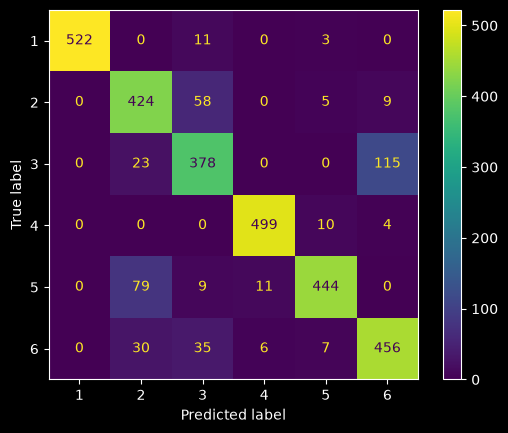

In [140]:
ConfusionMatrixDisplay.from_estimator(lda_best_estimator, X_test, y_test)

print(f"Search Time: {time.strftime('%H:%M:%S', time.gmtime(lda_search_time))} for {len(lda_best_models)} trials ({time.strftime('%H:%M:%S', time.gmtime(lda_search_time / len(lda_best_models)))} per trial)")
print(f"Best Parameters: {lda_best_params}")
print(f"Best Validation Score: {lda_best_score:.4f}\n")
print(f"Test Score: {accuracy_score(y_test, lda_best_estimator.predict(X_test)):.4f}")
print(f"F1 Score: {f1_score(y_test, lda_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Precision Score: {precision_score(y_test, lda_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Recall Score: {recall_score(y_test, lda_best_estimator.predict(X_test), average='macro'):.4f}")

### Random Forest Classifier

For the number of estimators and the maximum depth paramaters we do a separate round of tuning, since they control overfitting and model size rather than performance. We find that **125** estimators is about the sweet spot since performance gain beyond it is marginal with respect to the size increase of the model. For the maximum depth parameter we see that, without limits, the trees grow to no larger than 25 levels, and it seems like **10** is a nice middle ground between performance, size and overfitting.

In [ ]:
for param, opts in zip(['n_estimators', 'max_depth'], [list(range(25, 201, 25)), [None] + list(range(5, 51, 5))]):
    with warnings.catch_warnings():
        [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
        display(pd.DataFrame.from_dict(
            test_individual_parameter(get_pipeline((PCA(**TUNED_PARAMS['pca']), SelectKBest(**TUNED_PARAMS['selectkbest'])), model=RandomForestClassifier(random_state=RANDOM_STATE)), X_train, y_train, groups_train, param={param: opts}, step_idx=-1, n_jobs=-1, random_state=RANDOM_STATE), 
            orient='index', columns=['Train Score']).assign(Mistakes=lambda x: (1 - x['Train Score']) * len(X_train)).astype({'Mistakes': 'int64'}).sort_values(by='Train Score', ascending=False).reset_index(names=param))

Testing parameter 'n_estimators' for step 'randomforestclassifier':   0%|          | 0/8 [00:00<?, ?it/s]

,n_estimators,Train Score,Mistakes
0,200,0.883023,1192
1,175,0.882443,1198
2,150,0.882372,1199
3,125,0.882230,1200
4,100,0.881526,1208
5,75,0.880765,1215
6,50,0.878477,1239
7,25,0.870729,1318


Testing parameter 'max_depth' for step 'randomforestclassifier':   0%|          | 0/11 [00:00<?, ?it/s]

,max_depth,Train Score,Mistakes
0,15,0.883623,1186
1,20,0.882214,1201
2,10,0.882016,1203
3,25,0.881546,1207
4,None,0.881526,1208
5,35,0.881526,1208
6,30,0.881526,1208
7,45,0.881526,1208
8,40,0.881526,1208
9,50,0.881526,1208


Now we do a grid search for the remaining parameters.

In [201]:
assert rf_best_models, "Catching a 'run all' attempt which might destroy a saved output."

In [202]:
rf_best_estimator, rf_best_params, rf_best_score = get_best_model(rf_best_models).values()
display(rf_best_estimator)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer_1', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](6,)","[1,2,3,4,5,6]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,56
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('transformer_1.1', ...), ('transformer_1.2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


Search Time: 00:30:23 for 10 trials (00:03:02 per trial)
Best Parameters: {'model__bootstrap': True, 'model__ccp_alpha': 0.0, 'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_split': 2, 'model__n_estimators': 125, 'model__oob_score': True}
Best Validation Score: 0.8851

Test Score: 0.8923
F1 Score: 0.8922
Precision Score: 0.8941
Recall Score: 0.8923


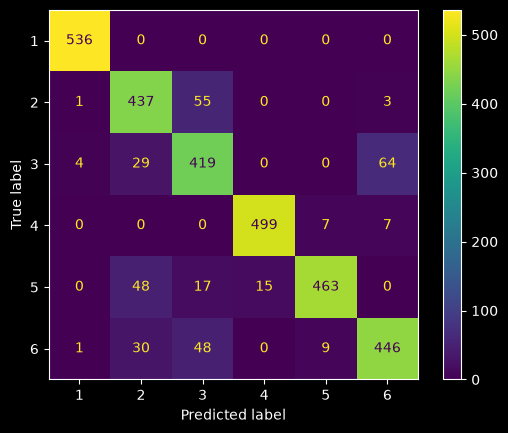

In [203]:
ConfusionMatrixDisplay.from_estimator(rf_best_estimator, X_test, y_test)

print(f"Search Time: {time.strftime('%H:%M:%S', time.gmtime(rf_search_time))} for {len(rf_best_models)} trials ({time.strftime('%H:%M:%S', time.gmtime(rf_search_time / len(rf_best_models)))} per trial)")
print(f"Best Parameters: {rf_best_params}")
print(f"Best Validation Score: {rf_best_score:.4f}\n")
print(f"Test Score: {accuracy_score(y_test, rf_best_estimator.predict(X_test)):.4f}")
print(f"F1 Score: {f1_score(y_test, rf_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Precision Score: {precision_score(y_test, rf_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Recall Score: {recall_score(y_test, rf_best_estimator.predict(X_test), average='macro'):.4f}")

### Logistic Regression

In [169]:
assert lr_best_models, "Catching a 'run all' attempt which might destroy a saved output."

In [171]:
lr_best_estimator, lr_best_params, lr_best_score = get_best_model(lr_best_models).values()
display(lr_best_estimator)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer_1', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](6,)","[1,2,3,4,5,6]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,56
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('transformer_1.1', ...), ('transformer_1.2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


Search Time: 00:02:10 for 10 trials (00:00:13 per trial)
Best Parameters: {'model__C': 0.001, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Best Validation Score: 0.8689

Test Score: 0.8744
F1 Score: 0.8750
Precision Score: 0.8804
Recall Score: 0.8742


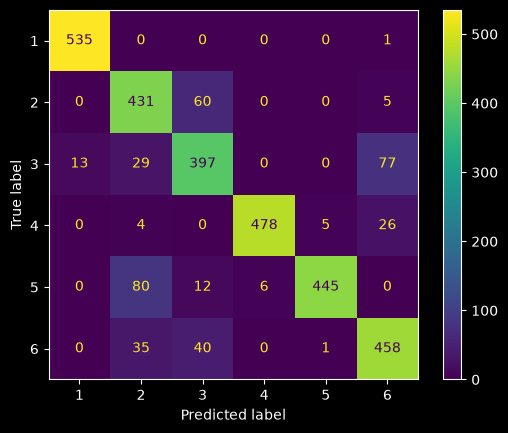

In [172]:
ConfusionMatrixDisplay.from_estimator(lr_best_estimator, X_test, y_test)

print(f"Search Time: {time.strftime('%H:%M:%S', time.gmtime(lr_search_time))} for {len(lr_best_models)} trials ({time.strftime('%H:%M:%S', time.gmtime(lr_search_time / len(lr_best_models)))} per trial)")
print(f"Best Parameters: {lr_best_params}")
print(f"Best Validation Score: {lr_best_score:.4f}\n")
print(f"Test Score: {accuracy_score(y_test, lr_best_estimator.predict(X_test)):.4f}")
print(f"F1 Score: {f1_score(y_test, lr_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Precision Score: {precision_score(y_test, lr_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Recall Score: {recall_score(y_test, lr_best_estimator.predict(X_test), average='macro'):.4f}")

### K-Nearest Neighbors

We first test different values for the amount of neighbors to find a balance between performance and overfitting. We find that a value of **70** would strike a nice balance.

In [ ]:
for param, opts in zip(['n_neighbors'], [list(range(5, 251, 5))]):
    with warnings.catch_warnings():
        [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
        display(pd.DataFrame.from_dict(
            test_individual_parameter(get_pipeline((PCA(**TUNED_PARAMS['pca']), SelectKBest(**TUNED_PARAMS['selectkbest'])), model="knn"), X_train, y_train, groups_train, param={param: opts}, step_idx=-1, n_jobs=-1, random_state=RANDOM_STATE), 
            orient='index', columns=['Train Score']).assign(Mistakes=lambda x: (1 - x['Train Score']) * len(X_train)).astype({'Mistakes': 'int64'}).sort_values(by='Train Score', ascending=False).reset_index(names=param))

Testing parameter 'n_neighbors' for step 'kneighborsclassifier':   0%|          | 0/50 [00:00<?, ?it/s]

,n_neighbors,Train Score,Mistakes
0,60,0.865156,1374
1,155,0.865126,1375
2,55,0.865091,1375
3,90,0.865085,1375
4,80,0.865058,1376
5,165,0.864993,1376
6,70,0.864758,1379
7,180,0.864721,1379
8,140,0.864702,1379
9,170,0.864696,1379


Now we again do a grid search for the remaining parameters.

In [194]:
assert knn_best_models, "Catching a 'run all' attempt which might destroy a saved output."

In [195]:
knn_best_estimator, knn_best_params, knn_best_score = get_best_model(knn_best_models).values()
display(knn_best_estimator)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer_1', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](6,)","[1,2,3,4,5,6]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,56
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('transformer_1.1', ...), ('transformer_1.2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


Search Time: 00:06:54 for 10 trials (00:00:41 per trial)
Best Parameters: {'model__algorithm': 'auto', 'model__n_neighbors': 70, 'model__p': 1, 'model__weights': 'distance'}
Best Validation Score: 0.8694

Test Score: 0.8901
F1 Score: 0.8895
Precision Score: 0.8915
Recall Score: 0.8893


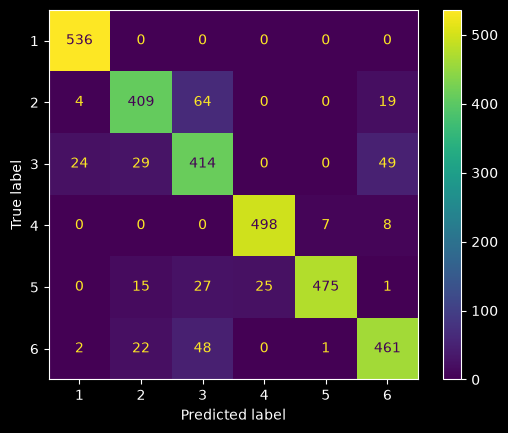

In [196]:
ConfusionMatrixDisplay.from_estimator(knn_best_estimator, X_test, y_test)

print(f"Search Time: {time.strftime('%H:%M:%S', time.gmtime(knn_search_time))} for {len(knn_best_models)} trials ({time.strftime('%H:%M:%S', time.gmtime(knn_search_time / len(knn_best_models)))} per trial)")
print(f"Best Parameters: {knn_best_params}")
print(f"Best Validation Score: {knn_best_score:.4f}\n")
print(f"Test Score: {accuracy_score(y_test, knn_best_estimator.predict(X_test)):.4f}")
print(f"F1 Score: {f1_score(y_test, knn_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Precision Score: {precision_score(y_test, knn_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Recall Score: {recall_score(y_test, knn_best_estimator.predict(X_test), average='macro'):.4f}")

### Multi-layer Perceptron Classifier

We first take a look at the effect of changing the amount and sizes of the hidden layers on the balance of performance and model size. After a few iterations, 2 hidden layers of sizes **(100, 50)** gives us this nice balance.

In [209]:
for param, opts in zip(['hidden_layer_sizes'], [[c for r in range(1, 4) for c in combinations_with_replacement([200, 100, 50], r)]]):
    with warnings.catch_warnings():
        [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
        display(pd.DataFrame.from_dict(
            test_individual_parameter(get_pipeline((PCA(**TUNED_PARAMS['pca']), SelectKBest(**TUNED_PARAMS['selectkbest'])), model=MLPClassifier(random_state=RANDOM_STATE)), X_train, y_train, groups_train, param={param: opts}, step_idx=-1, n_jobs=-1, random_state=RANDOM_STATE), 
            orient='index', columns=['Train Score']).assign(Mistakes=lambda x: (1 - x['Train Score']) * len(X_train)).astype({'Mistakes': 'int64'}).sort_values(by='Train Score', ascending=False).reset_index(names=param))

Testing parameter 'hidden_layer_sizes' for step 'mlpclassifier':   0%|          | 0/19 [00:00<?, ?it/s]

,hidden_layer_sizes,Train Score,Mistakes
0,"(200, 200, 100)",0.867179,1354
1,"(200, 200, 200)",0.861314,1414
2,"(100, 50)",0.860557,1421
3,"(100, 100, 50)",0.859894,1428
4,"(200, 100, 100)",0.859680,1430
5,"(200,)",0.859662,1431
6,"(100, 50, 50)",0.859601,1431
7,"(200, 100)",0.858875,1439
8,"(200, 50)",0.857202,1456
9,"(100, 100)",0.856183,1466


Now we again do a grid search for the remaining parameters.

In [212]:
assert mlp_best_models, "Catching a 'run all' attempt which might destroy a saved output."

In [214]:
mlp_best_estimator, mlp_best_params, mlp_best_score = get_best_model(mlp_best_models).values()
display(mlp_best_estimator)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer_1', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](6,)","[1,2,3,4,5,6]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,56
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('transformer_1.1', ...), ('transformer_1.2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


Search Time: 00:49:23 for 10 trials (00:04:56 per trial)
Best Parameters: {'model__activation': 'logistic', 'model__alpha': 0.1, 'model__learning_rate': 'constant', 'model__learning_rate_init': 0.001, 'model__momentum': 0.9, 'model__solver': 'sgd'}
Best Validation Score: 0.8805

Test Score: 0.8834
F1 Score: 0.8840
Precision Score: 0.8892
Recall Score: 0.8834


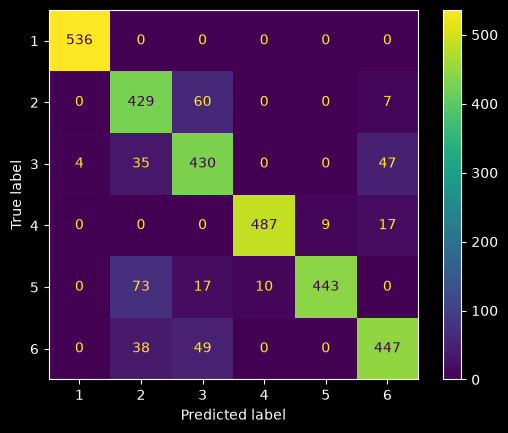

In [215]:
ConfusionMatrixDisplay.from_estimator(mlp_best_estimator, X_test, y_test)

print(f"Search Time: {time.strftime('%H:%M:%S', time.gmtime(mlp_search_time))} for {len(mlp_best_models)} trials ({time.strftime('%H:%M:%S', time.gmtime(mlp_search_time / len(mlp_best_models)))} per trial)")
print(f"Best Parameters: {mlp_best_params}")
print(f"Best Validation Score: {mlp_best_score:.4f}\n")
print(f"Test Score: {accuracy_score(y_test, mlp_best_estimator.predict(X_test)):.4f}")
print(f"F1 Score: {f1_score(y_test, mlp_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Precision Score: {precision_score(y_test, mlp_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Recall Score: {recall_score(y_test, mlp_best_estimator.predict(X_test), average='macro'):.4f}")

### Support Vector Classification

In [221]:
assert svc_best_models, "Catching a 'run all' attempt which might destroy a saved output."

In [222]:
svc_best_estimator, svc_best_params, svc_best_score = get_best_model(svc_best_models).values()
svc_best_estimator

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer_1', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](6,)","[1,2,3,4,5,6]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,56
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('transformer_1.1', ...), ('transformer_1.2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


Search Time: 01:04:34 for 10 trials (00:06:27 per trial)
Best Parameters: {'model__C': 1.0, 'model__break_ties': False, 'model__class_weight': 'balanced', 'model__gamma': 'scale', 'model__kernel': 'rbf', 'model__shrinking': False}
Best Validation Score: 0.8750

Test Score: 0.8866
F1 Score: 0.8865
Precision Score: 0.8898
Recall Score: 0.8863


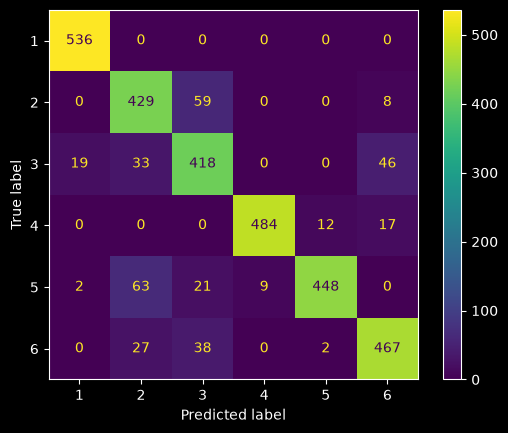

In [223]:
ConfusionMatrixDisplay.from_estimator(svc_best_estimator, X_test, y_test)

print(f"Search Time: {time.strftime('%H:%M:%S', time.gmtime(svc_search_time))} for {len(svc_best_models)} trials ({time.strftime('%H:%M:%S', time.gmtime(svc_search_time / len(svc_best_models)))} per trial)")
print(f"Best Parameters: {svc_best_params}")
print(f"Best Validation Score: {svc_best_score:.4f}\n")
print(f"Test Score: {accuracy_score(y_test, svc_best_estimator.predict(X_test)):.4f}")
print(f"F1 Score: {f1_score(y_test, svc_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Precision Score: {precision_score(y_test, svc_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Recall Score: {recall_score(y_test, svc_best_estimator.predict(X_test), average='macro'):.4f}")

### Ensemble model

The voting classifier only has a single tunable parameter, so it is evaluated manually. We find that 'hard' performs ever so slightly better, though the difference is negligible.

In [229]:
for param, opts in zip(['voting'], [['soft', 'hard']]):
    with warnings.catch_warnings():
        [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
        display(pd.DataFrame.from_dict(
            test_individual_parameter(get_pipeline(("pca", "kbest"), model=("rf", "mlp", "svc"), params=TUNED_PARAMS), X_train, y_train, groups_train, param={param: opts}, step_idx=-4, n_jobs=-1, random_state=RANDOM_STATE), 
            orient='index', columns=['Train Score']).assign(Mistakes=lambda x: (1 - x['Train Score']) * len(X_train)).astype({'Mistakes': 'int64'}).sort_values(by='Train Score', ascending=False).reset_index(names=param))

Testing parameter 'voting' for step 'votingclassifier':   0%|          | 0/2 [00:00<?, ?it/s]

,voting,Train Score,Mistakes
0,hard,0.883692,1185
1,soft,0.882908,1193


We now choose our best ensemble model, composed of the three best performing individual models, to run a final test on. 

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer_1', ...), ('ensemble_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](6,)","[1,2,3,4,5,6]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,56
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('transformer_1.1', ...), ('transformer_1.2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


Train Score: 0.9610
Test Score: 0.8955
F1 Score: 0.8957
Precision Score: 0.8995
Recall Score: 0.8954


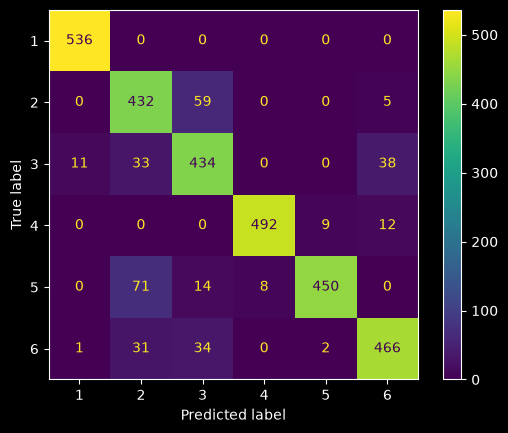

In [246]:
with warnings.catch_warnings():
    [warnings.filterwarnings("ignore", category=warn) for warn in [ConvergenceWarning, DeprecationWarning, FitFailedWarning, FutureWarning, UserWarning]]
    ensemble_best_estimator = get_pipeline(("pca", "kbest"), model=("rf", "mlp", "svc"), params=TUNED_PARAMS).fit(X_train, y_train)

display(ensemble_best_estimator)
with open("best_estimator.html", "w", encoding="utf-8") as f:
    f.write(estimator_html_repr(ensemble_best_estimator))

ConfusionMatrixDisplay.from_estimator(ensemble_best_estimator, X_test, y_test)

print(f"Train Score: {accuracy_score(y_train, ensemble_best_estimator.predict(X_train)):.4f}")
print(f"Test Score: {accuracy_score(y_test, ensemble_best_estimator.predict(X_test)):.4f}")
print(f"F1 Score: {f1_score(y_test, ensemble_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Precision Score: {precision_score(y_test, ensemble_best_estimator.predict(X_test), average='macro'):.4f}")
print(f"Recall Score: {recall_score(y_test, ensemble_best_estimator.predict(X_test), average='macro'):.4f}")

# Miscellaneous